# 11 — Bootstrap error bars on ρ₅₀ / ρ₉₀ and paired model comparisons

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What it does.** Attaches a statistical error to the headline numbers of notebooks 06–07 (extension 1 of the backlog). For every cached detector (logits of `cache/stats07.pkl`) and every morphology it computes ρ₅₀ and ρ₉₀ at FAP 10⁻² and 10⁻³ with a **bootstrap** that resamples *both* the validation background (threshold uncertainty) and the injections at each SNR, and tests paired differences between models (fresh vs static CNN, Transformer vs CNN) by bootstrapping the same background draw for both.

**What it does not do.** It does not retrain anything: the error is the *sampling* error of the test set and of the validation background for a fixed trained network. Seed-to-seed (training) scatter is a separate source, already reported in notebook 07 for the models that have two seeds.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pickle, os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import gwosc_tools as g
g.style()
ST = pickle.load(open(os.path.join(g.CACHE, "stats07.pkl"), "rb"))
SNRS = [3, 4, 5, 6, 7, 8, 9, 10, 12, 14, 16]; MORPHS = g.MORPHS; FAPS = (1e-2, 1e-3); B = 400
CEN = lambda r: SNRS[-1] if np.isnan(r) else r   # curve never reaches 50 %: censored at the largest injected SNR (bias towards 0 in differences)
print(len(ST), "cached models;", len(ST[list(ST)[0]]["val"]), "validation background windows")

12 cached models; 8112 validation background windows


## 1. Bootstrap ρ₅₀ and ρ₉₀ per model, morphology and FAP

In [2]:
rows = []
for name, s in ST.items():
    for far in FAPS:
        for kind in MORPHS:
            p, b = g.bootstrap_rho(s["val"], [s[(kind, r)] for r in SNRS], SNRS, far, B=B, seed=1)
            rows.append(dict(model=name, FAP=far, morph=kind, rho50=p[0], lo50=g.ci(b[:, 0])[0], hi50=g.ci(b[:, 0])[1],
                             rho90=p[1], lo90=g.ci(b[:, 1])[0], hi90=g.ci(b[:, 1])[1]))
D = pd.DataFrame(rows); D["err50"] = (D.hi50 - D.lo50) / 2
print("median 1-sigma half-width of rho50:", D.groupby("FAP").err50.median().round(3).to_dict())
D[D.model.isin(["cnn_static s0", "cnn_fresh s0"])].round(2)

median 1-sigma half-width of rho50: {0.001: 0.148, 0.01: 0.091}


,model,FAP,morph,rho50,lo50,hi50,rho90,lo90,hi90,err50
0,cnn_static s0,0.01,sg,5.59,5.46,5.69,7.71,7.61,7.81,0.12
1,cnn_static s0,0.01,pulse,4.64,4.57,4.76,6.52,6.44,6.59,0.09
2,cnn_static s0,0.01,chirp,5.77,5.67,5.85,7.72,7.65,7.81,0.09
3,cnn_static s0,0.00,sg,6.69,6.60,6.80,8.89,8.73,9.10,0.10
4,cnn_static s0,0.00,pulse,5.54,5.47,5.61,7.20,6.99,7.35,0.07
5,cnn_static s0,0.00,chirp,6.75,6.67,6.87,9.16,8.91,9.33,0.10
12,cnn_fresh s0,0.01,sg,4.69,4.60,4.80,6.96,6.89,7.13,0.10
13,cnn_fresh s0,0.01,pulse,4.19,4.07,4.28,5.99,5.92,6.18,0.10
14,cnn_fresh s0,0.01,chirp,4.83,4.66,5.00,6.92,6.82,7.07,0.17
15,cnn_fresh s0,0.00,sg,5.84,5.74,5.98,7.92,7.81,8.06,0.12


## 2. Mean ρ₅₀ over the three morphologies, with bootstrap interval

In [3]:
def mean_rho50(s, far, seed=1):
    # same bootstrap resample for every morphology (one background draw) -> interval of the mean
    rng = np.random.default_rng(seed); out = []
    for b in range(B):
        thr = g.threshold_at_far(rng.choice(s["val"], len(s["val"])), far)
        r = [CEN(g.snr_level([(rng.choice(s[(k, x)], len(s[(k, x)])) > thr).mean() for x in SNRS], SNRS, .5)) for k in MORPHS]
        out.append(np.mean(r))
    return np.array(out)
rows = []
for name, s in ST.items():
    for far in FAPS:
        b = mean_rho50(s, far); p = D[(D.model == name) & (D.FAP == far)].rho50.mean()
        lo, hi = g.ci(b); rows.append(dict(model=name, FAP=far, mean_rho50=p, lo=lo, hi=hi, err=(hi - lo) / 2))
M50 = pd.DataFrame(rows)
T = M50.pivot(index="model", columns="FAP", values="mean_rho50")
E = M50.pivot(index="model", columns="FAP", values="err")
T.join(E, lsuffix=" mean", rsuffix=" ±").sort_values("0.01 mean").round(2)

FAP,0.001 mean,0.01 mean,0.001 ±,0.01 ±
model,,,,
cnn_fresh s0,5.66,4.57,0.10,0.11
cnn_fresh s1,5.64,4.63,0.15,0.10
cnn_static s1,6.19,5.11,0.31,0.09
hyb_fresh s1,6.27,5.30,0.14,0.05
cnn_static s0,6.33,5.33,0.07,0.09
hyb_fresh s0,6.14,5.36,0.06,0.05
hyb_static s1,6.97,5.62,0.21,0.06
hyb_static s0,6.60,5.66,0.13,0.07
tf16_fresh s1,7.51,6.24,0.25,0.10


## 3. Paired differences (same background draw, same injections resampled independently)

In [4]:
def paired(a, b, far, seed=2):
    rng = np.random.default_rng(seed); out = []
    for _ in range(B):
        idx = rng.choice(len(ST[a]["val"]), len(ST[a]["val"]))   # same windows for both models
        ta, tb = g.threshold_at_far(ST[a]["val"][idx], far), g.threshold_at_far(ST[b]["val"][idx], far)
        ra, rb = [], []
        for k in MORPHS:
            for m, t, r in ((a, ta, ra), (b, tb, rb)):
                r.append(CEN(g.snr_level([(rng.choice(ST[m][(k, x)], len(ST[m][(k, x)])) > t).mean() for x in SNRS], SNRS, .5)))
        out.append(np.mean(ra) - np.mean(rb))
    return np.array(out)
pairs = [("cnn_fresh s0", "cnn_static s0"), ("tf16_fresh s0", "cnn_fresh s0"), ("hyb_fresh s0", "cnn_fresh s0"), ("cnn_fresh s0", "cnn_fresh s1"), ("tf16_fresh s0", "tf16_fresh s1")]
rows = []
for a, b in pairs:
    for far in FAPS:
        d = paired(a, b, far); lo, hi = np.percentile(d, [2.5, 97.5])
        rows.append(dict(A=a, B=b, FAP=far, delta=float(np.mean(d)), lo95=float(lo), hi95=float(hi), significant=bool(lo > 0 or hi < 0)))
P = pd.DataFrame(rows); P.round(3)

,A,B,FAP,delta,lo95,hi95,significant
0,cnn_fresh s0,cnn_static s0,0.010,-0.763,-0.994,-0.522,True
1,cnn_fresh s0,cnn_static s0,0.001,-0.686,-1.287,-0.398,True
2,tf16_fresh s0,cnn_fresh s0,0.010,1.710,1.471,1.937,True
3,tf16_fresh s0,cnn_fresh s0,0.001,1.602,1.234,2.232,True
4,hyb_fresh s0,cnn_fresh s0,0.010,0.790,0.577,0.992,True
5,hyb_fresh s0,cnn_fresh s0,0.001,0.452,0.133,0.703,True
6,cnn_fresh s0,cnn_fresh s1,0.010,-0.054,-0.275,0.172,False
7,cnn_fresh s0,cnn_fresh s1,0.001,0.023,-0.340,0.319,False
8,tf16_fresh s0,tf16_fresh s1,0.010,0.023,-0.152,0.222,False
9,tf16_fresh s0,tf16_fresh s1,0.001,-0.407,-1.828,0.009,False


## 4. Figure

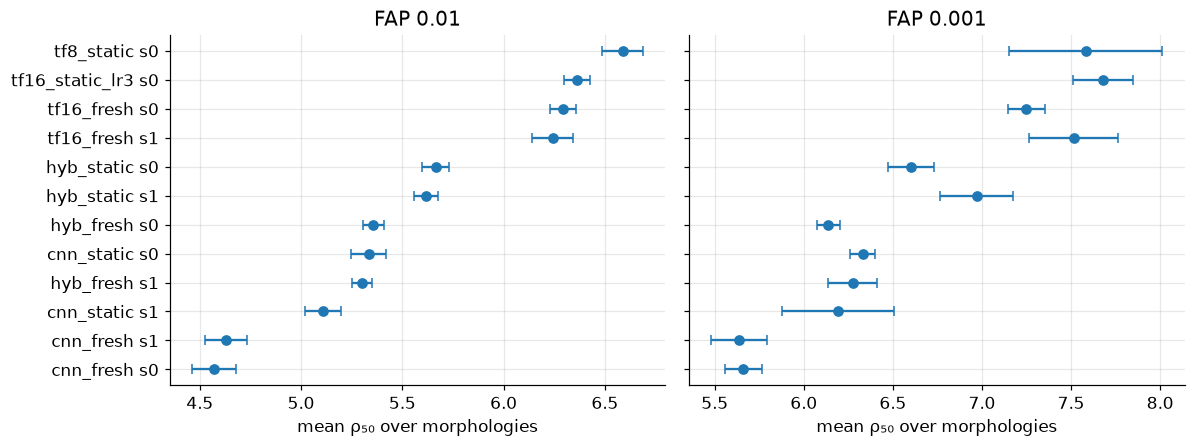

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
order = list(T.sort_values(0.01).index)
for a, far in zip(ax, FAPS):
    m = M50[M50.FAP == far].set_index("model").loc[order]
    a.errorbar(m.mean_rho50, range(len(m)), xerr=m.err, fmt="o", color=g.COLORS["freq"], capsize=3)
    a.set_yticks(range(len(m))); a.set_yticklabels(order); a.set_xlabel("mean ρ₅₀ over morphologies"); a.set_title(f"FAP {far:g}")
fig.tight_layout(); g.savefig(fig, "fig11_bootstrap_rho50"); plt.show()

In [6]:
g.save_json(dict(B=B, per_morph=D.to_dict("records"), mean_rho50=M50.to_dict("records"), paired=P.to_dict("records")), "11_summary.json"); print("saved")

saved


## Output and next step

`results/11_summary.json` (all intervals and paired tests) and `figures/fig11_bootstrap_rho50`. The intervals are the sampling error for a fixed network; compare them with the seed scatter of notebook 07 before calling a difference real. Next: unified thresholds across the report (extension 63).